# 03 — AI agent for heart-rate analysis

**Goal:** Answer questions about a recording segment using the computed results from notebook 02. The agent calls one analysis function; it never invents estimates or provides medical diagnoses.

The **ECG-derived reference** is used only to evaluate predictions produced from wrist signals. The notebook runs without an LLM; Ollama and OpenAI are optional alternatives.

## 2. Load the results

Change `SUBJECT`, `START`, and `DURATION` to choose your example. The printed table shows which timestamps are available in the **test set** (not the full recording).

In [19]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
from pprint import pprint

DATA_FILE = Path("../Data/test_predictions.csv")
SUBJECT = "S1"
START = 8000       # seconds from this subject's recording start
DURATION = 120     # seconds to analyze
WINDOW = 8         # same 8-second windows as notebook 02

if not DATA_FILE.exists():
    raise FileNotFoundError("Run the export cell in notebook 02 first: " + str(DATA_FILE))

predictions = pd.read_csv(DATA_FILE)

required = {
    "Subject", "Time (s)", "Reference HR (BPM)", "Spectral BPM",
    "ML estimate (BPM)", "ACC magnitude std"
}
assert required.issubset(predictions.columns), "Missing columns: " + str(required - set(predictions.columns))

display(predictions.groupby("Subject")["Time (s)"].agg(["min", "max", "count"]))

,min,max,count
Subject,,,
S1,7376.0,9208.0,917


## 3. One analysis tool

`analyze_segment()` selects **complete 8-second windows** inside the requested time range and summarizes the model against the ECG reference. It returns only computed numbers plus explicitly stated limitations. It does **not** use the ECG reference to produce estimates.

In [20]:
# Manual analysis
def analyze_segment(subject: str, start_seconds: float, duration_seconds: float) -> dict:
    """Analyze held-out heart-rate predictions for a subject and time segment.

    Args:
        subject: Participant ID, for example S1.
        start_seconds: Segment start, in seconds from recording start.
        duration_seconds: Segment length in seconds (at least 8).
    """
    start_seconds = float(start_seconds)
    duration_seconds = float(duration_seconds)

    if duration_seconds < WINDOW:
        return {"error": "The segment must be at least 8 seconds long."}

    end_seconds = start_seconds + duration_seconds
    rows = predictions[
        (predictions["Subject"] == subject) &
        (predictions["Time (s)"] - WINDOW / 2 >= start_seconds) &
        (predictions["Time (s)"] + WINDOW / 2 <= end_seconds)
    ]

    if rows.empty:
        return {"error": "No complete test windows in this range. Check the available subject/time ranges above."}

    reference = rows["Reference HR (BPM)"]
    baseline = rows["Spectral BPM"]
    ml = rows["ML estimate (BPM)"]

    return {
        "subject": subject,
        "requested_interval_s": [start_seconds, end_seconds],
        "windows_analyzed": int(len(rows)),
        "reference_mean_bpm": round(float(reference.mean()), 2),
        "spectral_mean_bpm": round(float(baseline.mean()), 2),
        "ml_mean_bpm": round(float(ml.mean()), 2),
        "spectral_mae_bpm": round(float((baseline - reference).abs().mean()), 2),
        "ml_mae_bpm": round(float((ml - reference).abs().mean()), 2),
        "ml_max_absolute_error_bpm": round(float((ml - reference).abs().max()), 2),
        "mean_wrist_movement_variability": round(float(rows["ACC magnitude std"].mean()), 3),
        "limitations": [
            "Reference HR comes from chest ECG and was used for evaluation only.",
            "These are overlapping 8-second windows, so observations are not independent.",
            "Movement variability alone cannot prove that an error is a motion artifact.",
            "This interval is from the held-out test portion of recorded participants.",
            "No medical diagnosis or clinical interpretation is supported."
        ]
    }

In [27]:
# Plot the exact test windows selected by analyze_segment().
import matplotlib.pyplot as plt


def plot_segment(subject: str, start_seconds: float, duration_seconds: float):
    end_seconds = start_seconds + duration_seconds
    rows = predictions[
        (predictions["Subject"] == subject) &
        (predictions["Time (s)"] - WINDOW / 2 >= start_seconds) &
        (predictions["Time (s)"] + WINDOW / 2 <= end_seconds)
    ].sort_values("Time (s)")

    if rows.empty:
        print("No complete test windows in this interval.")
        return

    fig, (ax_hr, ax_acc) = plt.subplots(
        2, 1, figsize=(12, 7), sharex=True,
        gridspec_kw={"height_ratios": [2, 1]}
    )

    ax_hr.plot(rows["Time (s)"], rows["Reference HR (BPM)"], label="ECG reference", linewidth=2)
    ax_hr.plot(rows["Time (s)"], rows["Spectral BPM"], label="Spectral estimate", linestyle="--")
    ax_hr.plot(rows["Time (s)"], rows["ML estimate (BPM)"], label="ML estimate", linestyle=":")
    ax_hr.set_ylabel("Heart rate (BPM)")
    ax_hr.legend()
    ax_hr.grid(alpha=0.2)

    ax_acc.plot(rows["Time (s)"], rows["ACC magnitude std"], color="tab:purple")
    ax_acc.set_ylabel("Movement variability")
    ax_acc.set_xlabel("Time from recording start (seconds)")
    ax_acc.grid(alpha=0.2)
    ax_acc.set_xlim(start_seconds, end_seconds)

    fig.suptitle(f"{subject}: analysis interval {start_seconds:g}–{end_seconds:g} s")
    plt.tight_layout()
    plt.show()
    print(f"Plotted {len(rows)} complete 8-second test windows (same selection as the analysis tool).")


## 4. Try the analysis tool (no LLM required)

This is the fallback demonstration if you cannot run a local LLM.

In [32]:
result = analyze_segment(SUBJECT, START, DURATION)
pprint(result)
# plot_segment(SUBJECT, START, DURATION)

{'limitations': ['Reference HR comes from chest ECG and was used for '
                 'evaluation only.',
                 'These are overlapping 8-second windows, so observations are '
                 'not independent.',
                 'Movement variability alone cannot prove that an error is a '
                 'motion artifact.',
                 'This interval is from the held-out test portion of recorded '
                 'participants.',
                 'No medical diagnosis or clinical interpretation is '
                 'supported.'],
 'mean_wrist_movement_variability': 0.024,
 'ml_mae_bpm': 4.63,
 'ml_max_absolute_error_bpm': 14.48,
 'ml_mean_bpm': 68.04,
 'reference_mean_bpm': 71.92,
 'requested_interval_s': [8000.0, 8120.0],
 'spectral_mae_bpm': 2.41,
 'spectral_mean_bpm': 71.0,
 'subject': 'S1',
 'windows_analyzed': 57}


## 5. Agent instructions (shared by Ollama and OpenAI)

The prompt explicitly separates **measured results**, **interpretations**, and **limitations**. It prevents clinical claims and keeps the agent grounded in the analysis function output.

In [22]:
SYSTEM_PROMPT = """You are a careful research assistant explaining a small wearable-sensor heart-rate prototype built using PPG-DaLiA.

Your job is to explain the results returned by the analyze_segment tool. You are not a clinician, and you do not perform heart-rate estimation yourself.

Rules:
1. Call analyze_segment before answering any request about a recording segment. Base every numerical claim on its output. Never invent measurements, activities, accuracy scores, trends, or facts about a participant.
2. Clearly separate (a) observations supported by tool values, (b) possible explanations or hypotheses, and (c) limitations / uncertainty. Use plain, concise language.
3. The heart-rate predictions were computed beforehand from wrist PPG (with accelerometer-derived features for the ML model). The ECG-derived reference was used ONLY for comparison/evaluation, never as a predictor input.
4. Explain that MAE describes error over the analyzed windows, not guaranteed accuracy on other time ranges or unseen participants. Treat differences cautiously, especially for short segments.
5. Motion variability may be related to estimation error, but it cannot establish that a specific movement caused a given artifact. Do not infer precise actions or physiological conditions.
6. Do not provide a medical diagnosis, advice about a person's health, fitness, safety, or treatment, or claim clinical validity. This is a research prototype, not a medical device.
7. If the tool reports an error, say which data are unavailable; do not invent an analysis. Acknowledge missing information and suggest a valid subject/time range.
8. Keep your answer focused: observations with units, brief comparison of spectral and ML estimates, uncertainty and limitations. If asked what to improve, suggest a modest, testable next step.

Never imply that you have inspected the raw signal unless it is part of the tool result. Do not claim the agent retrained the model or accessed unseen data."""

## 6. Option A — local AI agent (Ollama)

Optional: install `ollama` (`pip install ollama`), pull `qwen2.5:3b`, and start the Ollama service. The agent calls the same `analyze_segment` function, using the shared prompt above. No paid API is required.

In [29]:
def ask_agent(question: str):
    from ollama import chat

    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": question}
    ]

    # model_name = "medgemma:4b"  # doesn't support tool calls
    model_name = "qwen3:4b"
    reply = chat(model=model_name, messages=messages, tools=[analyze_segment])
    messages.append(reply.message)

    if not reply.message.tool_calls:
        print("The model did not call the analysis tool. Specify a subject and time range.")
        return

    for call in reply.message.tool_calls:
        if call.function.name != "analyze_segment":
            continue
        result = analyze_segment(**call.function.arguments)
        plot_segment(**call.function.arguments)
        messages.append({
            "role": "tool",
            "tool_name": "analyze_segment",
            "content": json.dumps(result)
        })

    answer = chat(model=model_name, messages=messages)
    print(answer.message.content)
    return answer.message.content

## 7. Option B — OpenAI API (tool calling)

Install once: `pip install openai`. This uses the OpenAI **Responses API** with a required function call. It sends only the requested question and the aggregated tool result (not raw PPG or acceleration samples).

The API key is written as a **placeholder in the cell**, as requested. Replace it locally if you run the example; **never commit an actual key** to Git or include it in the ZIP.

In [30]:
OPENAI_API_KEY = "PASTE_YOUR_OPENAI_API_KEY_HERE"
OPENAI_MODEL = "gpt-4.1-mini"

# The only tool the OpenAI model can call.
analysis_tool = {
    "type": "function",
    "name": "analyze_segment",
    "description": "Summarize previously computed heart-rate estimates and ECG-reference errors for a participant's held-out test interval.",
    "parameters": {
        "type": "object",
        "properties": {
            "subject": {"type": "string", "description": "Participant ID, e.g. S1"},
            "start_seconds": {"type": "number", "description": "Seconds from recording start"},
            "duration_seconds": {"type": "number", "description": "Segment duration in seconds, at least 8"}
        },
        "required": ["subject", "start_seconds", "duration_seconds"],
        "additionalProperties": False
    },
    "strict": True
}


def ask_openai(question: str):
    from openai import OpenAI


    client = OpenAI(api_key=OPENAI_API_KEY)
    messages = [{"role": "user", "content": question}]

    # Require the LLM to request our one analysis function.
    first = client.responses.create(
        model=OPENAI_MODEL,
        instructions=SYSTEM_PROMPT,
        input=messages,
        tools=[analysis_tool],
        tool_choice={"type": "function", "name": "analyze_segment"},
        parallel_tool_calls=False,
        store=False
    )

    calls = [item for item in first.output if item.type == "function_call"]
    if not calls:
        raise RuntimeError("The model did not call analyze_segment.")

    messages.extend(first.output)
    for call in calls:
        if call.name != "analyze_segment":
            raise ValueError(f"Unexpected function: {call.name}")
        args = json.loads(call.arguments)
        result = analyze_segment(**args)
        plot_segment(**args)
        print("Analysis result:")
        pprint(result)
        messages.append({
            "type": "function_call_output",
            "call_id": call.call_id,
            "output": json.dumps(result)
        })

    # Give the tool result back, then request an explanation (no further tools).
    final = client.responses.create(
        model=OPENAI_MODEL,
        instructions=SYSTEM_PROMPT,
        input=messages,
        tools=[analysis_tool],
        tool_choice="none",
        store=False
    )
    print("\nAgent response:\n" + final.output_text)
    return final.output_text

## 8. Ask a question

Both agents use `analyze_segment` and the same safety/evidence prompt. Keep the calls commented out if no LLM is installed or no API key is available; the direct analysis function above still demonstrates the tool.

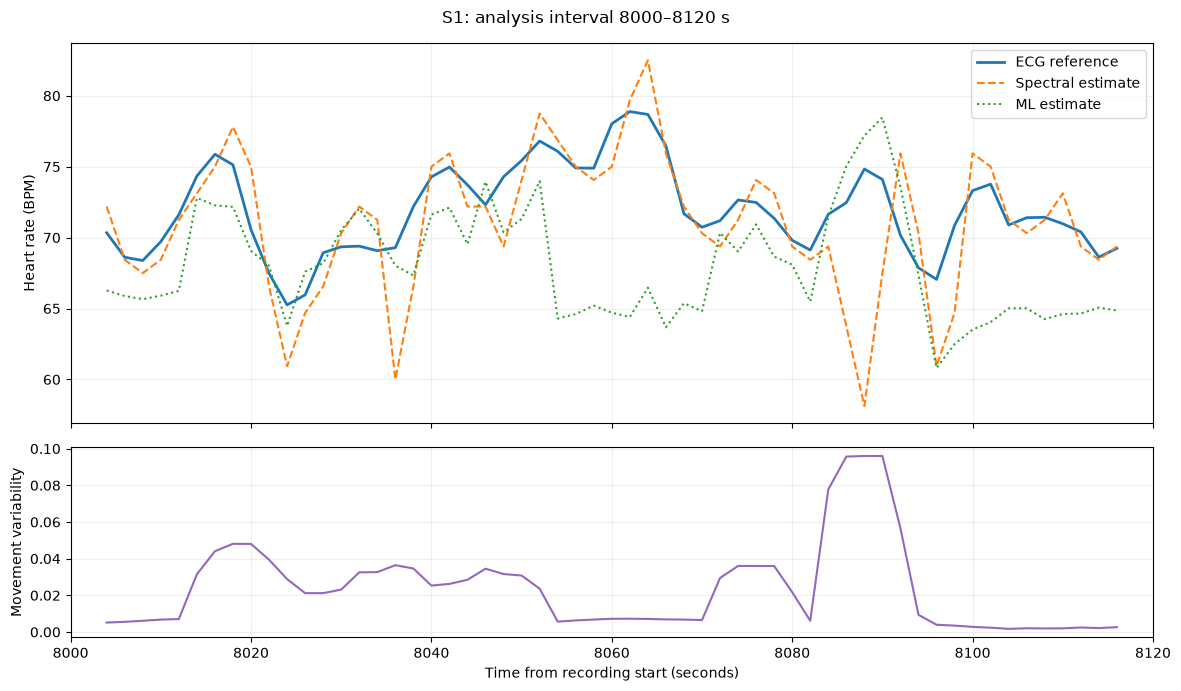

Plotted 57 complete 8-second test windows (same selection as the analysis tool).
(a) **Observations (directly from tool output)**  
- Spectral analysis (ECG reference): Mean HR = 71.0 BPM, MAE = 2.41 BPM  
- ML model (wrist PPG): Mean HR = 68.04 BPM, MAE = 4.63 BPM  
- Maximum absolute error for ML model: 14.48 BPM  
- Mean wrist movement variability: 0.024 (unit not specified in tool, but low)  

(b) **Possible explanations**  
The ML model’s higher MAE (4.63 BPM vs. spectral’s 2.41 BPM) may reflect greater sensitivity to motion artifacts in this segment, though the low movement variability (0.024) suggests this is unlikely to be the primary cause. The ML model’s maximum error (14.48 BPM) could indicate transient signal disruptions, but the tool does not link this to specific movements or physiological states.  

(c) **Limitations and uncertainty**  
- The ECG reference HR was used only for evaluation, not as input to the model.  
- Overlapping 8-second windows mean results are not st

In [31]:
question = (
    f"Analyze {SUBJECT} from {START} to {START + DURATION} seconds. "
    "What did you find, and what are the limitations?"
)

ans = ask_agent(question)   # Local Ollama option
# ans = ask_openai(question)  # OpenAI API option (needs your API key)